In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)



In [2]:
from pathlib import Path

train_candidates = [
    Path.cwd() / "Airline Satisfaction" / "train.csv",
    Path.cwd() / "train.csv",
]
train_path = next((path for path in train_candidates if path.is_file()), None)
if train_path is None:
    raise FileNotFoundError("Could not find train.csv in the workspace or current folder.")

df = pd.read_csv(train_path)
print(f"Loaded {len(df):,} rows from {train_path}")

Loaded 699,635 rows from /Users/ankurjoshi/PythonProject/Airline Satisfaction/train.csv


In [3]:
df.shape, df.head()

((699635, 23),
    id  Age  Flight Distance  Inflight wifi service  \
 0   0   36              694                      4   
 1   1   56              651                      5   
 2   2   31             1371                      3   
 3   3   10             1616                      3   
 4   4   23              481                      3   
 
    Departure/Arrival time convenient  Ease of Online booking  Gate location  \
 0                                  4                       4              3   
 1                                  5                       5              5   
 2                                  4                       2              5   
 3                                  5                       3              3   
 4                                  4                       3              4   
 
    Food and drink  Online boarding  Seat comfort  ...  Baggage handling  \
 0               1                4             1  ...                 4   
 1               5 

In [4]:
# df.groupby(['id']).count()['Age'].sort_values(asc = False)
df[df.groupby('id')['id'].transform('count') > 1]

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction


In [5]:
df.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.00000,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699343.000000
mean,349817.00000,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,3.517404,3.472847,3.805443,3.420291,3.380401,1.176209,1.134280
std,201967.37213,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,1.238474,1.271755,1.079175,1.210604,1.277870,5.982187,5.749304
min,0.00000,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,174908.50000,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,349817.00000,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000
75%,524725.50000,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000
max,699634.00000,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000


In [6]:
df.isnull().sum()

id                                     0
Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             292
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
satisfaction                           0
dtype: int64

In [7]:
# df[df['Arrival Delay in Minutes'].isnull()]

col = 'Arrival Delay in Minutes'

df['is_missing'] = df[col].isna()

df.groupby('is_missing').mean(numeric_only=True).T

is_missing,False,True
id,349820.496269,341443.400685
Age,39.002531,37.558219
Flight Distance,1353.798525,1306.301370
Inflight wifi service,2.778757,2.695205
Departure/Arrival time convenient,3.156138,3.328767
Ease of Online booking,2.813262,2.760274
Gate location,3.013706,3.082192
Food and drink,3.265625,3.311644
Online boarding,3.364226,3.195205
Seat comfort,3.568968,3.523973


In [8]:
df = df.dropna(subset=['Arrival Delay in Minutes'])

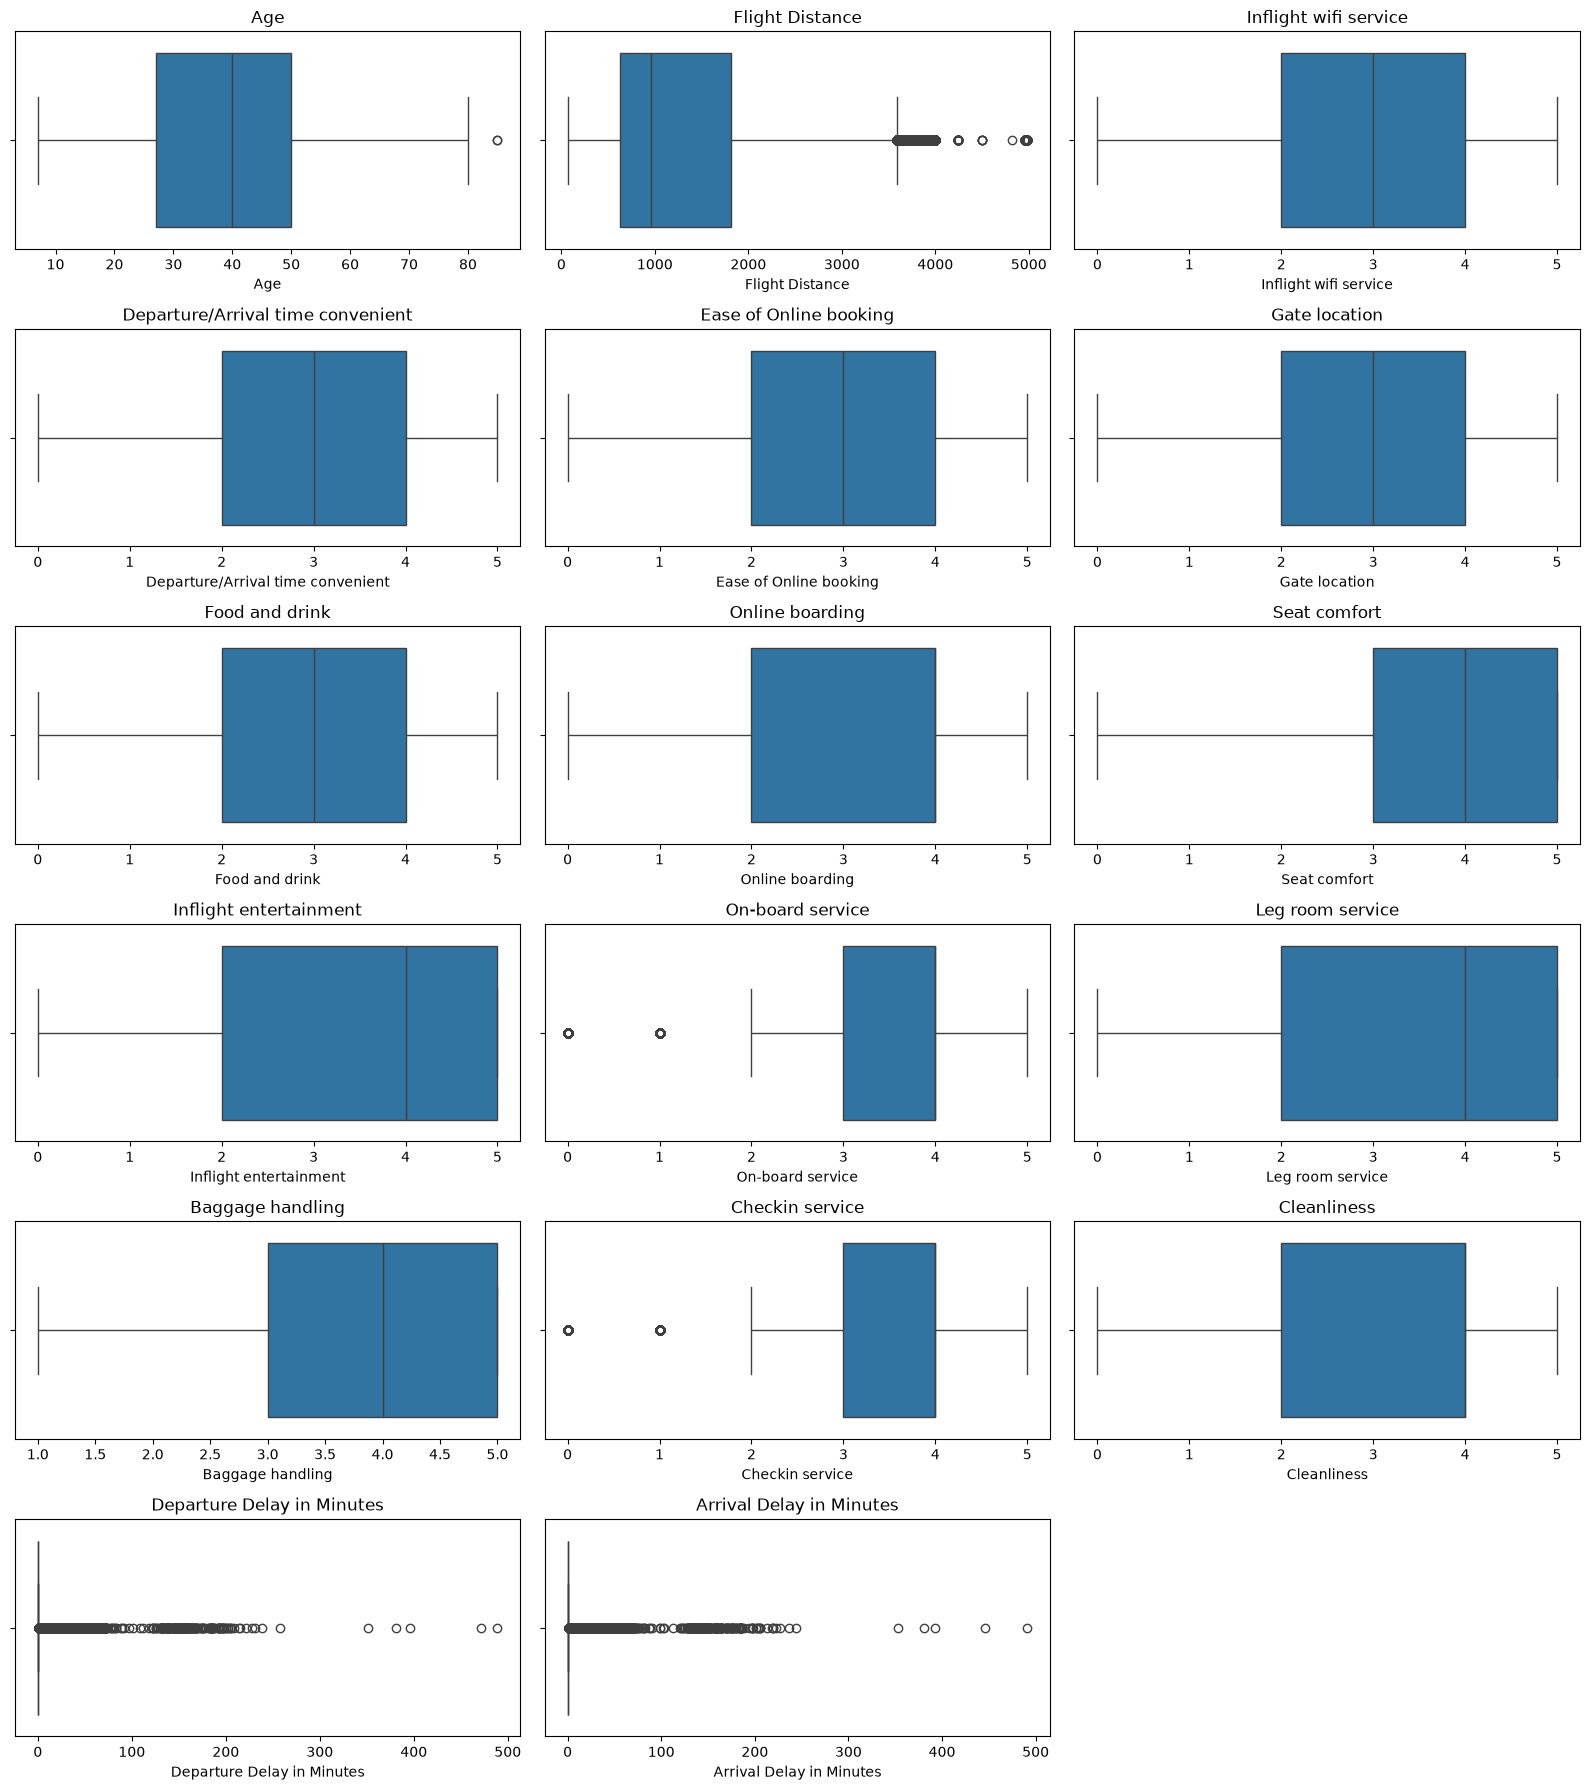

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

num_cols = df.select_dtypes(include='number').columns.drop('id', errors='ignore')

ncols = 3
nrows = math.ceil(len(num_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 3))

for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

# Hide unused plots
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

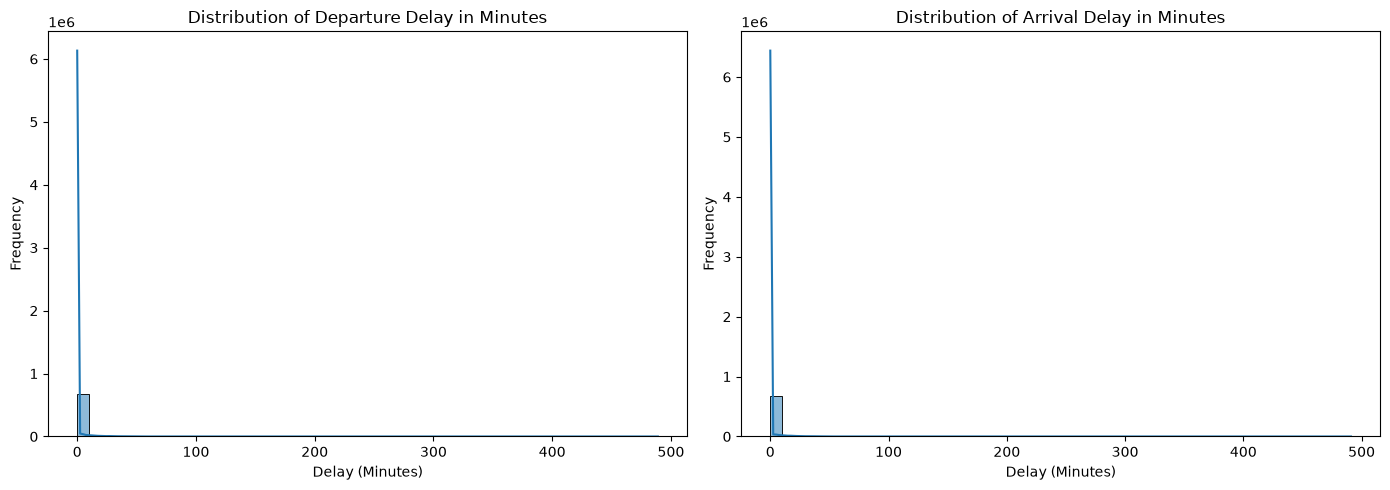

In [10]:
cols = ['Departure Delay in Minutes', 'Arrival Delay in Minutes']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, cols):
    sns.histplot(data=df, x=col, bins=50, kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel('Delay (Minutes)')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [11]:
cols = [
    'Departure Delay in Minutes',
    'Arrival Delay in Minutes'
]


for col in cols:
    upper = df[col].quantile(0.99)
    df[col] = df[col].clip(upper=upper)

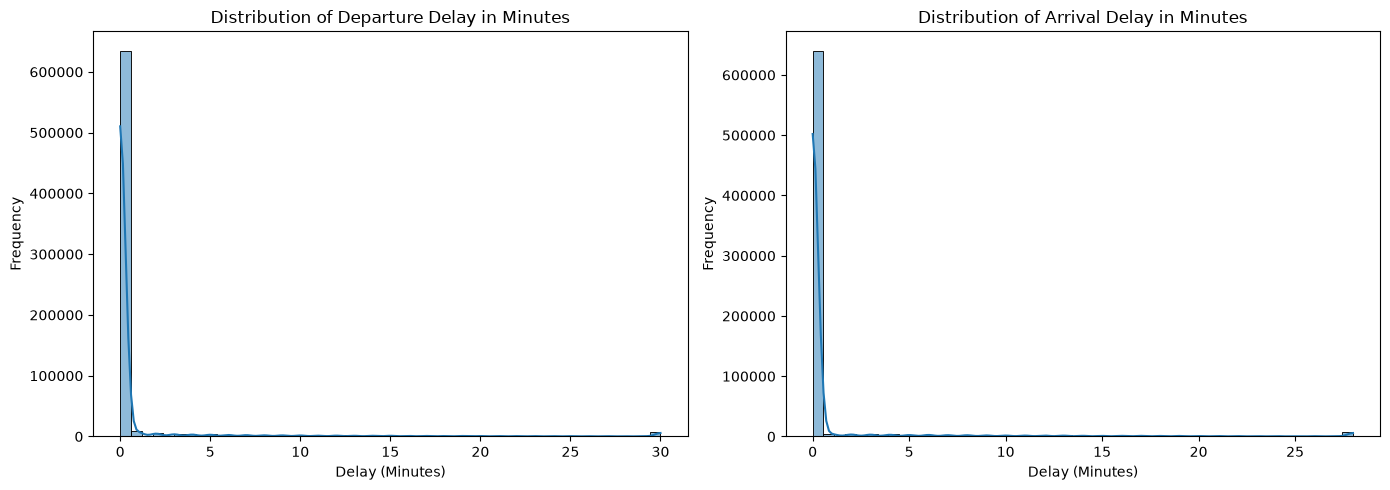

In [12]:
cols = ['Departure Delay in Minutes', 'Arrival Delay in Minutes']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, cols):
    sns.histplot(data=df, x=col, bins=50, kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel('Delay (Minutes)')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

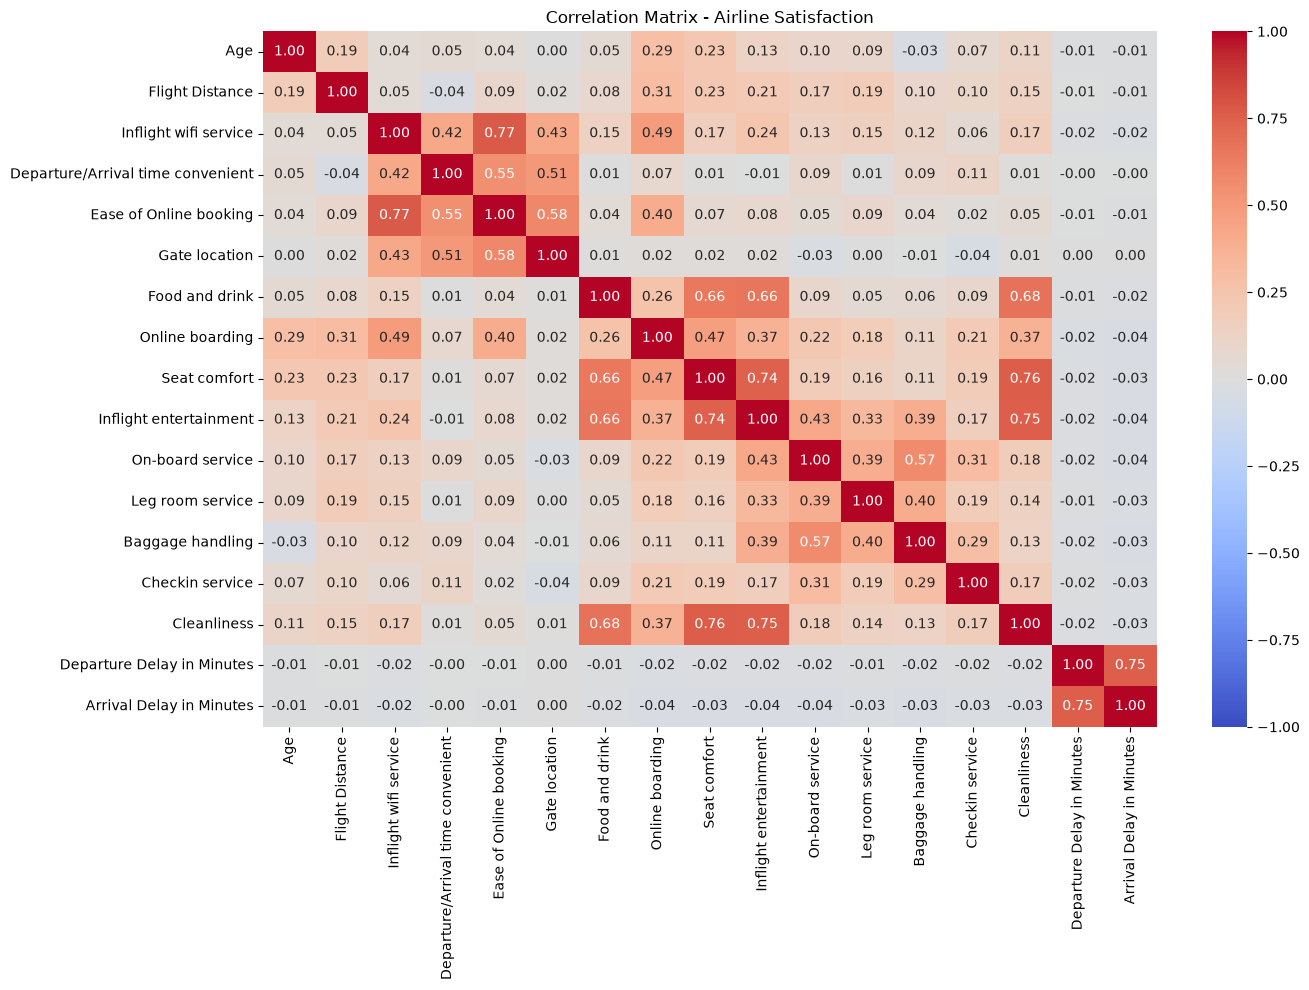

In [13]:


# Select numerical columns, excluding ID
num_cols = df.select_dtypes(include='number').columns.drop(
    'id', errors='ignore'
)

corr_matrix = df[num_cols].corr(method='pearson')

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix - Airline Satisfaction')
plt.tight_layout()
plt.show()

In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler
import pandas as pd

X = df.select_dtypes(include='number').drop(
    columns=['id', 'is_missing'],
    errors='ignore'
)

X = X.loc[:, X.nunique() > 1].dropna()

X_scaled = StandardScaler().fit_transform(X)

vif = pd.DataFrame({
    'Feature': X.columns,
    'VIF': [
        variance_inflation_factor(X_scaled, i)
        for i in range(X_scaled.shape[1])
    ]
})

vif.sort_values('VIF', ascending=False)

,Feature,VIF
9,Inflight entertainment,4.653954
4,Ease of Online booking,3.632970
8,Seat comfort,3.593653
14,Cleanliness,3.266290
2,Inflight wifi service,2.978819
16,Arrival Delay in Minutes,2.330221
15,Departure Delay in Minutes,2.325614
6,Food and drink,2.291452
7,Online boarding,2.203550
12,Baggage handling,1.817885


## Model training and comparison

We will compare five classifiers for `satisfaction`. Numeric and categorical preprocessing stays inside each pipeline, so it is fit independently within each cross-validation fold. Each model is tuned using stratified 5-fold randomized search on the full labeled training set. The best cross-validation metrics form the comparison table, and each winning model is refit on all labeled training data. The separate `test.csv` has no `satisfaction` labels, so it cannot be used to calculate performance metrics.

### Step 1: Import tools, set reproducibility options, and load the raw data

In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

RANDOM_STATE = 42
CV_FOLDS = 5
N_ITER = 3

# train_candidates = [
#     Path.cwd() / "Airline Satisfaction" / "train.csv",
#     Path.cwd() / "train.csv",
# ]
# train_path = next((path for path in train_candidates if path.is_file()), None)
# if train_path is None:
#     raise FileNotFoundError("Could not find train.csv in the workspace or current folder.")

model_data = pd.read_csv('/Users/ankurjoshi/PythonProject/Airline Satisfaction/train.csv')
if "satisfaction" not in model_data:
    raise KeyError("The training data must contain the 'satisfaction' target column.")
print(f"Loaded {len(model_data):,} rows from {'/Users/ankurjoshi/PythonProject/Airline Satisfaction/train.csv'}")

Loaded 699,635 rows from /Users/ankurjoshi/PythonProject/Airline Satisfaction/train.csv


### Step 2: Separate features and target

The `id` column is excluded because it identifies records rather than describing passengers. The labeled training data will be used in all five CV folds; the separate test set is unlabeled.

In [20]:
X = model_data.drop(columns=["satisfaction", "id"], errors="ignore")
y = model_data["satisfaction"].astype(int)
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print(f"Features: {len(numeric_features)} numeric, {len(categorical_features)} categorical")
print(f"Labeled rows used for 5-fold CV: {len(X_train):,}")

Features: 17 numeric, 4 categorical
Labeled rows used for 5-fold CV: 699,635


### Step 3: Build preprocessing pipelines

Median imputation and standardization are applied to numeric features. Categorical features use most-frequent imputation and one-hot encoding. Because these transformers are in the estimator pipeline, each CV fold learns preprocessing only from its training fold.

In [21]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ]
)

# Verify the preprocessor can fit and transform a small training sample.
preprocessor_preview = clone(preprocessor).fit_transform(X_train.iloc[:100])
print("Transformed sample shape:", preprocessor_preview.shape)

Transformed sample shape: (100, 26)


### Step 4: Specify candidate models and randomized search spaces

Each model will receive three randomly sampled hyperparameter combinations. Increase `N_ITER` for a broader search at the cost of additional runtime.

In [22]:
model_search_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2_000, solver="liblinear", random_state=RANDOM_STATE),
        {
            "model__C": loguniform(1e-3, 1e2),
            "model__class_weight": [None, "balanced"],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
        {
            "model__n_estimators": [150, 250],
            "model__max_depth": [None, 20, 35],
            "model__min_samples_leaf": [1, 2, 5],
            "model__max_features": ["sqrt", 0.7],
            "model__class_weight": [None, "balanced_subsample"],
        },
    ),
    "XGBoost": (
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=-1,
            random_state=RANDOM_STATE,
        ),
        {
            "model__n_estimators": [120, 200],
            "model__max_depth": [3, 5, 7],
            "model__learning_rate": loguniform(0.02, 0.2),
            "model__subsample": [0.8, 1.0],
            "model__colsample_bytree": [0.8, 1.0],
            "model__reg_lambda": loguniform(0.1, 10),
        },
    ),
    "Neural Network": (
        MLPClassifier(
            early_stopping=True,
            max_iter=150,
            n_iter_no_change=6,
            random_state=RANDOM_STATE,
        ),
        {
            "model__hidden_layer_sizes": [(64,), (128,), (64, 32)],
            "model__alpha": loguniform(1e-5, 1e-2),
            "model__learning_rate_init": loguniform(1e-4, 3e-3),
            "model__batch_size": [256],
        },
    ),
    "SVM (Linear)": (
        LinearSVC(dual="auto", max_iter=5_000, random_state=RANDOM_STATE),
        {
            "model__C": loguniform(1e-3, 1e2),
            "model__class_weight": [None, "balanced"],
        },
    ),
}

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
print(f"Prepared {len(model_search_spaces)} models and {CV_FOLDS}-fold stratified CV.")

Prepared 5 models and 5-fold stratified CV.


### Step 5: Tune each model with 5-fold randomized search

F1 selects each model's best hyperparameter combination. The search also records accuracy, balanced accuracy, precision, recall, and ROC-AUC across folds. With the full dataset, this cell runs `5 × N_ITER` fits per model and may take a while.

In [23]:
scoring_metrics = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}
search_results = {}

for model_name, (estimator, param_distributions) in model_search_spaces.items():
    print(f"\nTuning {model_name} ({N_ITER} candidates, {CV_FOLDS}-fold CV)...")
    pipeline = Pipeline(
        steps=[("preprocess", clone(preprocessor)), ("model", estimator)]
    )
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions,
        n_iter=N_ITER,
        scoring=scoring_metrics,
        refit="f1",
        cv=cv,
        n_jobs=1,
        random_state=RANDOM_STATE,
        verbose=1,
    )
    search.fit(X, y)
    search_results[model_name] = search
    print(f"Best mean CV F1: {search.best_score_:.4f}")
    print("Best parameters:", search.best_params_)


Tuning Logistic Regression (3 candidates, 5-fold CV)...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best mean CV F1: 0.8608
Best parameters: {'model__C': np.float64(0.0745934328572655), 'model__class_weight': None}

Tuning Random Forest (3 candidates, 5-fold CV)...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best mean CV F1: 0.9154
Best parameters: {'model__n_estimators': 150, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 35, 'model__class_weight': 'balanced_subsample'}

Tuning XGBoost (3 candidates, 5-fold CV)...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best mean CV F1: 0.9150
Best parameters: {'model__colsample_bytree': 0.8, 'model__learning_rate': np.float64(0.12519096368575075), 'model__max_depth': 7, 'model__n_estimators': 120, 'model__reg_lambda': np.float64(3.625617634576228), 'model__subsample': 0.8}

Tuning Neural Network (3 candidates, 5-fold CV)...
Fitting 5 folds for each of 3 candidates,

### Step 6: Refit the best models and compare cross-validation performance

Each randomized search refits its best-F1 configuration on all labeled training data. The table reports the mean 5-fold CV score for every metric for each model's selected configuration; it does not claim performance on the unlabeled test set.

In [24]:
fitted_models = {}
result_rows = []

for model_name, search in search_results.items():
    # With refit="f1", best_estimator_ is already fitted on all labeled rows.
    fitted_models[model_name] = search.best_estimator_
    best_index = search.best_index_
    cv_results = search.cv_results_

    result_rows.append(
        {
            "Model": model_name,
            "Best CV Accuracy": cv_results["mean_test_accuracy"][best_index],
            "Best CV Balanced Accuracy": cv_results["mean_test_balanced_accuracy"][best_index],
            "Best CV Precision": cv_results["mean_test_precision"][best_index],
            "Best CV Recall": cv_results["mean_test_recall"][best_index],
            "Best CV F1": cv_results["mean_test_f1"][best_index],
            "Best CV ROC-AUC": cv_results["mean_test_roc_auc"][best_index],
            "Best Parameters": search.best_params_,
        }
    )

performance_table = (
    pd.DataFrame(result_rows)
    .sort_values(["Best CV F1", "Best CV ROC-AUC"], ascending=False)
    .reset_index(drop=True)
)
metric_columns = [
    "Best CV Accuracy",
    "Best CV Balanced Accuracy",
    "Best CV Precision",
    "Best CV Recall",
    "Best CV F1",
    "Best CV ROC-AUC",
]
performance_table[metric_columns] = performance_table[metric_columns].round(4)
display(performance_table)
print(f"Top model by mean CV F1: {performance_table.loc[0, 'Model']}")

,Model,Best CV Accuracy,Best CV Balanced Accuracy,Best CV Precision,Best CV Recall,Best CV F1,Best CV ROC-AUC,Best Parameters
0,Random Forest,0.9256,0.9238,0.9235,0.9075,0.9154,0.9558,"{'model__n_estimators': 150, 'model__min_sampl..."
1,XGBoost,0.9256,0.9233,0.9269,0.9035,0.9150,0.9583,"{'model__colsample_bytree': 0.8, 'model__learn..."
2,Neural Network,0.9240,0.9218,0.9249,0.9019,0.9133,0.9566,"{'model__alpha': 2.9375384576328295e-05, 'mode..."
3,Logistic Regression,0.8784,0.8752,0.8744,0.8475,0.8608,0.9216,"{'model__C': 0.0745934328572655, 'model__class..."
4,SVM (Linear),0.8764,0.8733,0.8718,0.8457,0.8585,0.9206,"{'model__C': 0.0745934328572655, 'model__class..."


Top model by mean CV F1: Random Forest
